In [1]:
import numpy as np
import sys
import os

project_root = os.path.abspath(os.path.join(os.getcwd(),'..'))
print(project_root)
sys.path.append(project_root)

from scripts.analyze_attention import (
    load_npz_safely,
    analyze_one_data_record,
    analyze_one_npz_record

)


/home/user/projects/objectVLA


In [2]:
data_path = f"{str(project_root)}/outputs/libero_eval/episodes_npz/task_000_episode_000.npz"
data = load_npz_safely(data_path)


In [3]:
from analysis.attention.constants import TASK_TO_OBJECT
from analysis.attention.figures import (
        
        save_attention_summary_figure

)
from analysis.attention.metrics import (
        get_object_names,
)
from analysis.attention.metrics import (
        _extract_patch_attention,
        _build_heatmap_overlay
        )
object_name = get_object_names(data, TASK_TO_OBJECT)
object_name



'orange juice'

In [4]:
from typing import Any, Dict, List, Optional

import numpy as np
import torch
def to_torch_attention_list(attn_obj: Any) -> List[torch.Tensor]:
    """
    Convert action_attentions loaded from npz into List[torch.Tensor].
    Expected per layer shape: [B, H, Q, K]
    """
    if isinstance(attn_obj, torch.Tensor):
        return [attn_obj]

    if isinstance(attn_obj, np.ndarray):
        # if attn_obj.dtype == object:
            layers = attn_obj.tolist()
        # else:
        #     # If only one tensor-like array stored
        #     layers = [attn_obj]
    elif isinstance(attn_obj, list):
        layers = attn_obj
    else:
        raise TypeError(f"Unsupported attention object type: {type(attn_obj)}")

    out = []
    for x in layers:
        if isinstance(x, torch.Tensor):
            out.append(x.detach().cpu().to(torch.float32))
        else:
            out.append(torch.tensor(np.asarray(x), dtype=torch.float32))
    return out

In [5]:
action_attentions = data['attention_maps'][0]
front_images = data['front_images'][0]
wrist_images = data['wrist_images'][0]
print(action_attentions.shape)
print(front_images.shape)
print(wrist_images.shape)

(1, 1, 1, 51, 867)
(256, 256, 3)
(256, 256, 3)


In [6]:
data

{'task_id': 0,
 'episode_idx': 0,
 'task_description': 'pick up the alphabet soup and place it in the basket',
 'success': True,
 'initial_state': array([ 0.        , -0.01723539, -0.13168156, -0.00551779, -2.45947659,
         0.01130304,  2.22927339,  0.77834666,  0.020833  , -0.020833  ,
        -0.12      , -0.24      ,  0.015     ,  0.        ,  0.        ,
         0.70710678,  0.70710678,  0.01483492,  0.25214199,  0.035     ,
         0.70710678,  0.        ,  0.        ,  0.70710678,  0.05      ,
        -0.1       ,  0.035     ,  0.5       ,  0.5       ,  0.5       ,
         0.5       , -0.1512778 ,  0.05836388,  0.        ,  0.        ,
         0.        ,  0.        ,  1.        ,  0.10437769, -0.19603159,
         0.035     ,  0.5       ,  0.5       ,  0.5       ,  0.5       ,
         0.15      ,  0.03      ,  0.035     ,  0.        ,  0.        ,
         0.70710678,  0.70710678, -0.20462353, -0.07527224, -0.005     ,
         0.        ,  0.        ,  0.        ,  1. 

In [7]:
base_extracted = _extract_patch_attention(
        action_attentions=action_attentions,
        image_token_slice= slice(0, 256),
)

wrist_extracted = _extract_patch_attention(
        action_attentions=action_attentions,
        image_token_slice= slice(256, 512),
)
base_extracted

{'patch_scores': array([3.36123449e-05, 2.74648846e-05, 2.27362507e-05, 2.16107746e-05,
        2.00306677e-05, 2.12176179e-04, 4.20870297e-02, 1.84062887e-02,
        7.98332912e-04, 1.31854822e-05, 1.50846499e-05, 1.54083846e-05,
        1.50075148e-05, 1.47118290e-05, 1.44406858e-05, 1.46405373e-05,
        1.53344097e-02, 1.56312082e-02, 1.27328606e-02, 2.59112194e-02,
        2.91721113e-02, 5.77521212e-02, 5.04446588e-02, 1.02532143e-03,
        3.22554624e-05, 5.98288025e-04, 3.98585387e-03, 3.96001106e-03,
        2.38025133e-02, 1.08556189e-02, 3.18903080e-03, 3.36912577e-03,
        1.73543009e-03, 1.87158585e-03, 3.43434955e-03, 4.37336322e-03,
        1.77221857e-02, 3.40033509e-03, 9.59366007e-05, 1.03209532e-05,
        1.17529603e-03, 3.87522765e-03, 2.54530068e-02, 2.51120776e-02,
        1.95517447e-02, 2.03203689e-02, 1.54872965e-02, 1.82791315e-02,
        2.68213428e-03, 5.45249274e-03, 5.72688924e-03, 5.68434782e-03,
        1.56538154e-05, 1.47772771e-05, 1.339935

In [8]:
for key, value in wrist_extracted.items():
    print(f"{key}: {value.shape}")

patch_scores: (256,)
all_action_patch_attn: (51, 256)
mean_action_attention: (51, 867)


In [9]:
base_overlay =_build_heatmap_overlay(
        patch_scores=base_extracted['patch_scores'],
        alpha=0.3,
        image=front_images,
        )
wrist_overlay =_build_heatmap_overlay(
        patch_scores=wrist_extracted['patch_scores'],
        alpha=0.3,
        image=wrist_images,
        )

In [10]:
from scripts.analyze_attention import (
    get_attention_overlay_figure,
)

res = get_attention_overlay_figure(
        mean_action_attention=base_extracted["mean_action_attention"],
        base_img=base_overlay["overlay_bgr()"], 
        wrist_img=wrist_overlay["overlay_bgr()"], 
        base_max =base_overlay["max_value()"],
        wrist_max =wrist_overlay["max_value()"],
        mode="mean", 
        object_name=object_name,
        sample_id=0,
        top_k=5)


True

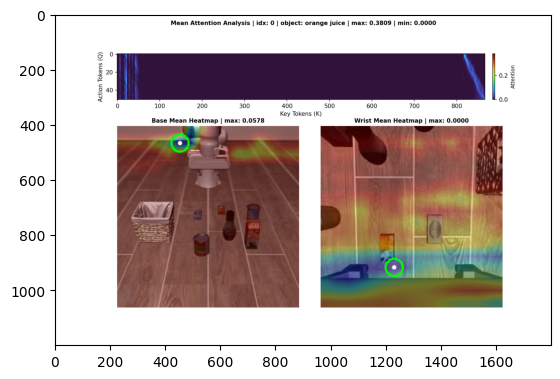

In [11]:
from matplotlib import pyplot as plt
import cv2
plt.imshow(res)
res = cv2.cvtColor(res, cv2.COLOR_RGB2BGR)
cv2.imwrite("test_overlay.png", res)

In [12]:
from analysis.attention.configs import AnalysisConfig


action_attentions  = to_torch_attention_list(action_attentions)
config = AnalysisConfig(
        layer_idx=-1,            # last layer
        # head_idx=None,       # unique head
        action_token_idx=-1,     # average over action rows
        alpha=0.3,
        top_k=5,
        patch_grid_size=16,
        save_overlay_figures=False,
        save_mean_summary_figure=False,
        save_cluster_summary_figures=False,
    )


row = analyze_one_data_record(
        sample_id= data['task_id'],
        episode_idx=data['episode_idx'],
        action_attention=action_attentions,
        image_inputs={
            "base_img": front_images,
            "wrist_img": wrist_images,
        },
        object_name=object_name,
        config=config,
)

True

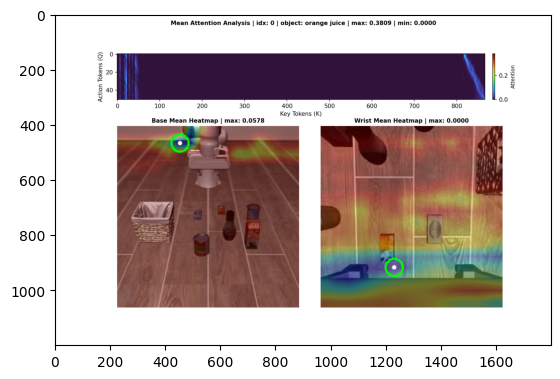

In [13]:
heat_map = row.pop("heatmap_overlay_figure")

plt.imshow(heat_map)
heat_map = cv2.cvtColor(heat_map, cv2.COLOR_RGB2BGR)
cv2.imwrite("test_overlay.png", heat_map)

In [14]:
row

{'sample_id': 0,
 'episode_idx': 0,
 'object_name': 'orange juice',
 'entropy(base_img)': 3.157026645755787,
 'gini(base_img)': 0.9298832460608923,
 'top5_share(base_img)': 0.40885410374195197,
 'max_attention_value(base_img)': 0.05775212123990059,
 'max_patch(base_img)': '{"rank": 1, "patch_idx": 21, "row": 1, "col": 5, "value": 0.05775212123990059, "share": 0.11497551027138571}',
 'topk_patches(base_img)': '[{"rank": 1, "patch_idx": 21, "row": 1, "col": 5, "value": 0.05775212123990059, "share": 0.11497551027138571}, {"rank": 2, "patch_idx": 22, "row": 1, "col": 6, "value": 0.05044465884566307, "share": 0.10042748676110906}, {"rank": 3, "patch_idx": 6, "row": 0, "col": 6, "value": 0.04208702966570854, "share": 0.08378874416613752}, {"rank": 4, "patch_idx": 20, "row": 1, "col": 4, "value": 0.029172111302614212, "share": 0.058077146097872075}, {"rank": 5, "patch_idx": 19, "row": 1, "col": 3, "value": 0.02591121941804886, "share": 0.05158521644544763}]',
 'max_point_xy(base_img)': (88, 2

In [15]:
all_rows,sample_id = analyze_one_npz_record(
        record=data,
        file_path=data_path,
        episode_key="episode_idx",
        config=config,
        sample_id= data['task_id'],
        attention_key="attention_maps",
        output_dir=project_root + "/outputs/libero_eval/analysis_results",
        base_img_keys=["front_images"],
        wrist_img_keys=["wrist_images"],
)

object_name orange juice
2026-04-17 13:39:30,486 - imageio_ffmpeg - WARNING - IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1800, 1200) to (1808, 1200) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).
2026-04-17 13:39:31,674 - src.utils.video_utils - INFO - Saved heatmap MP4 at path /home/user/projects/objectVLA/outputs/libero_eval/analysis_results/heatmaps/task_idx_0_episode_0_142_orange juice.mp4


In [16]:
data

{'task_id': 0,
 'episode_idx': 0,
 'task_description': 'pick up the alphabet soup and place it in the basket',
 'success': True,
 'initial_state': array([ 0.        , -0.01723539, -0.13168156, -0.00551779, -2.45947659,
         0.01130304,  2.22927339,  0.77834666,  0.020833  , -0.020833  ,
        -0.12      , -0.24      ,  0.015     ,  0.        ,  0.        ,
         0.70710678,  0.70710678,  0.01483492,  0.25214199,  0.035     ,
         0.70710678,  0.        ,  0.        ,  0.70710678,  0.05      ,
        -0.1       ,  0.035     ,  0.5       ,  0.5       ,  0.5       ,
         0.5       , -0.1512778 ,  0.05836388,  0.        ,  0.        ,
         0.        ,  0.        ,  1.        ,  0.10437769, -0.19603159,
         0.035     ,  0.5       ,  0.5       ,  0.5       ,  0.5       ,
         0.15      ,  0.03      ,  0.035     ,  0.        ,  0.        ,
         0.70710678,  0.70710678, -0.20462353, -0.07527224, -0.005     ,
         0.        ,  0.        ,  0.        ,  1. 

In [17]:
data['attention_maps']

array([[[[[[1.55258179e-03, 1.23882294e-03, 9.96589661e-04, ...,
            0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
           [2.44379044e-06, 2.38418579e-06, 2.32458115e-06, ...,
            1.75762177e-03, 5.08117676e-03, 3.97491455e-03],
           [1.07288361e-06, 1.25169754e-06, 1.31130219e-06, ...,
            1.03664398e-03, 1.79576874e-03, 2.04277039e-03],
           ...,
           [7.09295273e-06, 6.97374344e-06, 6.49690628e-06, ...,
            3.70483398e-02, 2.61993408e-02, 2.47802734e-02],
           [4.58955765e-06, 4.35113907e-06, 4.05311584e-06, ...,
            3.86657715e-02, 6.93359375e-02, 6.56738281e-02],
           [8.34465027e-07, 7.74860382e-07, 7.74860382e-07, ...,
            4.36096191e-02, 6.79931641e-02, 6.97021484e-02]]]]],




       [[[[[1.55258179e-03, 1.23882294e-03, 9.96589661e-04, ...,
            0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
           [2.44379044e-06, 2.38418579e-06, 2.32458115e-06, ...,
            1.75762177e-03, 5